Samajhna pehle: Kal Precision dekhi (flag kiye hue customers mein se kitne sach mein churner the). Aaj uska jodidaar metric aata hai.

- Recall = TP / (TP + FN). Sawaal: “jitne customers sach mein churn karne wale the, unme se model ne kitne pakde?”
- F1-Score = 2 × (Precision × Recall) / (Precision + Recall). Yeh dono ka harmonic mean hai, aur ek hi number mein dono ko balance karta hai.

Yeh point khaas yaad rakhna (PDF ka note): Imbalanced data mein Accuracy se zyada Recall aur F1 important hote hain. Churn mein FN (churner miss hua) aam taur par mehenga hota hai, isliye Recall business ke liye bahut maayne rakhta hai.

Aaj ka rule: Threshold ka chunav sirf CV ke out-of-fold predictions se hoga. Test set par chuna hua threshold sirf ek baar lagega, aur uske baad kuch badalna nahi.

1. Setup:

In [2]:
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (confusion_matrix, precision_score, recall_score, f1_score, fbeta_score,
                             balanced_accuracy_score, precision_recall_curve, classification_report)
from sklearn.model_selection import StratifiedKFold, cross_val_predict

X_train = pd.read_csv('../data/processed/X_train.csv')
y_train = pd.read_csv('../data/processed/y_train.csv').squeeze()
X_test = pd.read_csv('../data/processed/X_test.csv')
y_test = pd.read_csv('../data/processed/y_test.csv').squeeze()

models = {
    'Logistic Regression': joblib.load('models/logreg_pipeline.joblib'),
    'Decision Tree (tuned)': joblib.load('models/decision_tree_tuned.joblib'),
}
prevalence = y_test.mean()

2. Formulas ko hath se verify karo:

In [3]:
for name, m in models.items():
    pred = m.predict(X_test)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    p = tp / (tp + fp) if (tp + fp) else 0.0
    r = tp / (tp + fn)
    f1 = 2 * p * r / (p + r) if (p + r) else 0.0
    print(f"{name}: recall {r:.3f} (sklearn {recall_score(y_test, pred):.3f}) | "
          f"F1 {f1:.3f} (sklearn {f1_score(y_test, pred):.3f})")

Logistic Regression: recall 0.739 (sklearn 0.739) | F1 0.764 (sklearn 0.764)
Decision Tree (tuned): recall 0.734 (sklearn 0.734) | F1 0.758 (sklearn 0.758)


3. F1 arithmetic mean kyun nahi hai? Ek extreme example:

In [4]:
p, r = 1.0, 0.01        # model bahut kam customers flag karta hai, par jo karta hai wo sab sahi
print("Arithmetic mean:", (p + r) / 2)
print("F1 (harmonic)  :", round(2 * p * r / (p + r), 4))

Arithmetic mean: 0.505
F1 (harmonic)  : 0.0198


Arithmetic mean 0.505 deta hai, jo model ko achha dikhata hai, jabki wo 100 churners mein se sirf 1 pakadta hai. Harmonic mean us galti ko pakad leta hai, kyunki wo kam wale number ki taraf kheenchta hai. Isliye F1 tabhi ooncha aata hai jab Precision aur Recall dono theek hon.

4. Baselines (F1 bhi dhokha de sakta hai):

In [5]:
rows = []
for label, d in {'Hamesha majority class': DummyClassifier(strategy='most_frequent'),
                 'Hamesha CHURN bolo': DummyClassifier(strategy='constant', constant=1)}.items():
    d.fit(X_train, y_train)
    p = d.predict(X_test)
    rows.append({'model': label,
                 'precision': precision_score(y_test, p, zero_division=0),
                 'recall': recall_score(y_test, p),
                 'F1': f1_score(y_test, p)})
print(pd.DataFrame(rows).round(3))
print(f"\n'Hamesha CHURN' ka F1 formula se: {2 * prevalence / (1 + prevalence):.3f}")

                    model  precision  recall     F1
0  Hamesha majority class      0.566     1.0  0.723
1      Hamesha CHURN bolo      0.566     1.0  0.723

'Hamesha CHURN' ka F1 formula se: 0.723


Zaroori seekh: “Hamesha CHURN bolo” ka Recall seedha 1.0 hota hai, kyunki wo har churner ko flag kar deta hai. Agar tumhare data mein churn kaafi common hai, to us bewakoof model ka F1 bhi accha-khasa aa jaata hai. Isliye kisi bhi model ke F1 ko hamesha is baseline se compare karo.

5. Apne models ka scoreboard:

In [6]:
rows = []
for name, m in models.items():
    p = m.predict(X_test)
    rows.append({'model': name,
                 'accuracy': (p == y_test).mean(),
                 'precision': precision_score(y_test, p, zero_division=0),
                 'recall': recall_score(y_test, p),
                 'F1': f1_score(y_test, p),
                 'recall (class 0)': recall_score(y_test, p, pos_label=0),
                 'balanced_acc': balanced_accuracy_score(y_test, p)})
print(pd.DataFrame(rows).set_index('model').round(3))

                       accuracy  precision  recall     F1  recall (class 0)  \
model                                                                         
Logistic Regression       0.742      0.791   0.739  0.764             0.745   
Decision Tree (tuned)     0.735      0.784   0.734  0.758             0.736   

                       balanced_acc  
model                                
Logistic Regression           0.742  
Decision Tree (tuned)         0.735  


recall (class 0) ko specificity kehte hain (active customers ko sahi pehchanne ki taakat). Balanced accuracy = dono recalls ka average.

6. classification_report (ek saath sab):

In [7]:
print(classification_report(y_test, models['Logistic Regression'].predict(X_test),
                            target_names=['Active', 'Churn'], digits=3))

              precision    recall  f1-score   support

      Active      0.687     0.745     0.715       459
       Churn      0.791     0.739     0.764       598

    accuracy                          0.742      1057
   macro avg      0.739     0.742     0.739      1057
weighted avg      0.746     0.742     0.743      1057



support har class ke asli customers ki ginti hai. macro avg dono classes ko barabar tolta hai, weighted avg unke size ke hisaab se.

7. Precision-Recall trade-off (sabse zaroori chart):

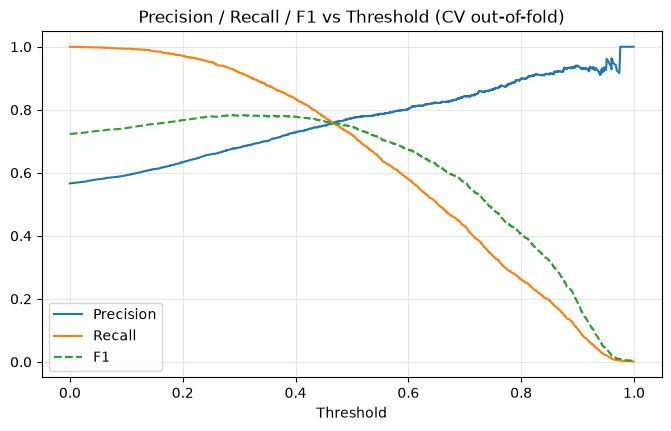

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof = cross_val_predict(models['Logistic Regression'], X_train, y_train, cv=cv, method='predict_proba')[:, 1]

prec, rec, thr = precision_recall_curve(y_train, oof)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)

plt.figure(figsize=(8, 4.5))
plt.plot(thr, prec[:-1], label='Precision')
plt.plot(thr, rec[:-1], label='Recall')
plt.plot(thr, f1s, label='F1', linestyle='--')
plt.xlabel('Threshold')
plt.title('Precision / Recall / F1 vs Threshold (CV out-of-fold)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Threshold badhane par Recall girta hai aur Precision aam taur par badhti hai. Yeh seesaw hai, aur yahi reason hai ki dono ko saath dekhna padta hai.

8. Threshold chuno CV se, aur test par sirf ek baar lagao:

In [9]:
best_t = thr[f1s.argmax()]
print(f"CV ke hisaab se F1-best threshold: {best_t:.2f}")

proba_test = models['Logistic Regression'].predict_proba(X_test)[:, 1]
rows = []
for label, t in [('default 0.5', 0.5), (f'CV-F1-best {best_t:.2f}', best_t)]:
    p = (proba_test >= t).astype(int)
    rows.append({'threshold': label, 'flagged': int(p.sum()),
                 'precision': precision_score(y_test, p, zero_division=0),
                 'recall': recall_score(y_test, p), 'F1': f1_score(y_test, p)})
print(pd.DataFrame(rows).round(3))

CV ke hisaab se F1-best threshold: 0.29
         threshold  flagged  precision  recall     F1
0      default 0.5      559      0.791   0.739  0.764
1  CV-F1-best 0.29      821      0.676   0.928  0.782


Is table ko dekh kar best_t dobara mat badalna. Agar badla, to test set tuning ka hissa ban gaya.

9. F2 aur F0.5 (jab Recall ya Precision ko zyada tolna ho):

In [10]:
for beta in [0.5, 1, 2]:
    p = (proba_test >= 0.5).astype(int)
    print(f"F{beta}: {fbeta_score(y_test, p, beta=beta):.3f}")

F0.5: 0.780
F1: 0.764
F2: 0.749


beta > 1 Recall ko zyada weight deta hai (churn mein useful, jab churner miss karna mehenga ho). beta < 1 Precision ko zyada weight deta hai (jab campaign mehengi ho).

10. Recall@k (campaign budget ka dusra sawaal):

In [11]:
order = np.argsort(-proba_test)
y_sorted = y_test.values[order]
total_churners = y_sorted.sum()

rows = []
for frac in [0.05, 0.10, 0.20, 0.30, 0.50]:
    k = int(len(y_sorted) * frac)
    caught = y_sorted[:k].sum()
    rows.append({'budget (top %)': int(frac * 100), 'churners caught': int(caught),
                 'recall@k': caught / total_churners})
print(pd.DataFrame(rows).round(3))

   budget (top %)  churners caught  recall@k
0               5               50     0.084
1              10               96     0.161
2              20              184     0.308
3              30              265     0.443
4              50              425     0.711


Kal precision@k ne bataya ki flagged customers mein kitne sahi hain. Aaj recall@k batata hai ki kul churners mein se kitne % pakde gaye. Dono ko saath padho.

11. Recall par bharosa kitna kare (confidence interval):

In [12]:
from statsmodels.stats.proportion import proportion_confint

p = models['Logistic Regression'].predict(X_test)
caught = int(((p == 1) & (y_test.values == 1)).sum())
n_churn = int(y_test.sum())
lo, hi = proportion_confint(caught, n_churn, method='wilson')
print(f"Recall {caught / n_churn:.3f}  (95% CI {lo:.3f} - {hi:.3f}, churners in test = {n_churn})")

Recall 0.739  (95% CI 0.702 - 0.773, churners in test = 598)


12. Business cost ke hisaab se threshold (Day 71 ke assumed costs wapas):

In [13]:
COST_FN, COST_FP, BENEFIT_TP = 50, 5, 40     # ASSUMPTIONS, apne hisaab se badlo

rows = []
for t in np.linspace(0.1, 0.9, 17):
    pred_t = (oof >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, pred_t).ravel()
    rows.append({'threshold': round(t, 2), 'net_value': tp * BENEFIT_TP - fp * COST_FP - fn * COST_FN})
cost_df = pd.DataFrame(rows)
print(cost_df.loc[cost_df['net_value'].idxmax()])

threshold        0.1
net_value    86180.0
Name: 0, dtype: float64


Dhyan do ki best business threshold aksar F1-best threshold se alag hota hai, kyunki F1 maanta hai ki Precision aur Recall barabar important hain. Business mein aisa nahi hota.

practice questions:

1. COST_FP ko 5 se 40 karke section 12 dobara chalao. Best threshold kis taraf khisakta hai, aur kyun?

2. Decision Tree ke liye bhi section 10 ka recall@k table banao. Kaunsa model chhote budget par zyada churners pakadta hai?

3. Apne shabdon mein likho: agar ek churner ko miss karna ek faltu discount dene se 10 guna mehenga hai, to F1, F2 ya precision mein se kaunsa metric dekhoge aur kyun?